# Particiones y balanceo: los conjuntos que verá cada modelo

> 🧭 **En 30 segundos**
> - **Para qué:** preparar, para cada modelo, **qué ventanas usa para entrenar, validar y evaluar**.
> - **Entra:** `ventanas.csv` → **Sale:** `conjuntos/<modelo>.csv` (una tabla por modelo) + `pliegues_ausencia.csv`.
> - **Idea clave:** se equilibra **solo el entrenamiento**, y **paciente a paciente**. dev y eval se quedan como en la realidad.

> 📍 **Dónde estamos: Fase 2 · notebook 4 de 4.** `03_ventanas` dejó un índice con todas las ventanas de 4 s y a qué modelos pertenece cada una. Este notebook decide **cuántas 💤 interictales se quedan** y reparte los pacientes. Es el último paso antes de entrenar.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| **Fase 2** | **Preprocesado y ventanas** | 👉 **en curso** (la fase de este notebook) |
| Fase 3 | Modelo de predicción (⏳ preictal frente a 💤 interictal) | pendiente |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## Qué hace este notebook

1. **Comprueba** que ningún paciente está en dos particiones (sección 3).
2. Pone un **máximo de horas de 💤 interictal por paciente**, para que ninguno domine (sección 4).
3. Arma un **conjunto por modelo**: general, comparación de umbrales, uno por grupo de inicio, test común y clasificación (sección 5).
4. **Equilibra el entrenamiento** paciente a paciente: tantas 💤 interictales como ⏳ preictales (sección 6).
5. Reparte en **pliegues** a los pacientes de 🟩 absz (🔹) de train + dev, para la validación cruzada (sección 7).

Como en `03`, **no se borra nada**: el entrenamiento equilibrado es una columna (`entrenamiento_equilibrado`), así que en la Fase 3 se puede entrenar con él o con todo y pesos de clase.

**Requisito**: haber ejecutado `03_ventanas` (aunque sea en modo prueba).

## Los notebooks de la Fase 2

| | Notebook | Qué hace | Entrada → salida | Estado |
|---|---|---|---|---|
| | `01_seleccion_crisis` | Elige qué señal se usa: tramos 💤 interictal, ⏳ preictal y ⚡ ictal. | Inventario → `tramos.csv` | ✅ |
| | `02_preprocesado` | Deja la señal en un formato común (TCP 22 canales, 256 Hz, filtrada, float16). | EDF → `senales/*.npy` + `senales.csv` | ✅ |
| | `03_ventanas` | Corta en ventanas de 4 s, decide a qué modelo pertenece cada una y marca las de mala calidad. | `senales.csv` → `ventanas.csv` | ✅ |
| 👉 | `04_particiones_y_balanceo` | **Limita las 💤 interictales por paciente, arma un conjunto por modelo y equilibra solo el entrenamiento.** | `ventanas.csv` → `conjuntos/*.csv` | **este notebook** |

## 1. Importación de librerías

Las reglas están en `tfm_comun/prediccion/`: `balanceo.py` (máximo y equilibrado por paciente) y `pliegues.py` (reparto en pliegues). El notebook solo las aplica y enseña el resultado.

In [46]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_02
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.dataset.particiones import SPLITS
from tfm_comun.dataset.tipos_crisis import GRUPOS
from tfm_comun.prediccion.umbrales import UMBRALES_LEADIN_COMPARACION_MIN
from tfm_comun.prediccion.ventanas import VENTANA_S
from tfm_comun.prediccion.balanceo import (SEMILLA, ventanas_en_horas, limitar_por_paciente,
                                           equilibrar_por_paciente, pesos_de_clase)
from tfm_comun.prediccion.pliegues import pliegues_por_paciente
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos, ICONO_GRUPO
from tfm_comun.visual.colores import COLORES_SPLIT, COLORES_PERIODO, COLOR_DESTACADO
from tfm_comun.visual.numeros import numero_legible
from tfm_comun.visual.ejes import eje_log_legible
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero

versiones_usadas = mostrar_versiones(np, pd, matplotlib)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2


## Conceptos clave

- **Partición por paciente**: TUSZ ya viene repartido así (🔵 train, 🟡 dev, 🟢 eval) y **ningún paciente está en dos**. Si lo estuviera, el modelo vería al paciente al entrenar y la nota de eval saldría inflada. Aquí solo se comprueba.
- **Máximo por paciente**: hay pacientes con decenas de horas de 💤 interictal (en 🟡 dev, uno tiene ~99 h de 338). Se queda como mucho **2 h por paciente** (sorteadas entre todos sus ficheros), **en todas las particiones**. Así ningún paciente pesa más que los demás juntos, ni al entrenar ni en las métricas.
- **Equilibrado (solo entrenamiento)**: cada paciente aporta **tantas 💤 interictales como ⏳ preictales suyas**. Las clases quedan equilibradas, y además **dentro de cada paciente**: el modelo no puede acertar reconociendo al paciente en vez de al EEG. Un paciente sin ⏳ preictales no aporta 💤 interictales al entrenamiento.
- **dev y eval no se equilibran**: tienen que parecerse a la realidad (muchas más 💤 interictales que ⏳ preictales). Si no, las falsas alarmas por hora y la precisión saldrían mejor de lo que son.
- **Conjunto**: las ventanas que usa **un** modelo. Hay uno por modelo, porque cada modelo tiene su ⏳ preictal (umbral y SPH distintos) y sus pacientes.
- **Validación cruzada por paciente**: con pocos pacientes (🟩 absz (🔹): 8 en train, 4 en dev y **1 solo en eval**), se reparten los de train + dev en **pliegues**. Se entrena con todos menos uno y se valida con ese, rotando. Así la cifra no depende de un único paciente.

## 2. Configuración

| Parámetro | Valor | Qué controla |
|---|---|---|
| `MAX_HORAS_INTERICTAL_POR_PACIENTE` | 2 | Horas de 💤 interictal que se quedan como mucho de cada paciente (todas las particiones). Con todos los datos, la mediana es ~1 h por paciente en 🔵 train, así que solo recorta a los que tienen mucho más |
| `RATIO_ENTRENAMIENTO` | 1 | 💤 interictales por cada ⏳ preictal dentro de cada paciente en el entrenamiento equilibrado (1 = mitad y mitad) |
| `EQUILIBRADO_EXACTO` | `True` | Cada paciente queda **exactamente** en `RATIO_ENTRENAMIENTO`: si le faltan 💤, se sortean también sus ⏳, y un paciente sin 💤 no entra en el entrenamiento. Lo pidió `05_auditoria_atajos`: si un paciente aporta más ⏳ que 💤, sus rasgos fijos (equipo, canales a 0) se vuelven una pista. Con `False`, se quedan todas las ⏳ |
| `GRUPOS_VALIDACION_CRUZADA` | `['ausencia']` | Grupos de inicio cuyo modelo se evalúa con validación cruzada por paciente en train + dev |
| `N_PLIEGUES` | 4 | Pliegues de esa validación cruzada (si hay menos pacientes, uno por paciente) |

La **semilla** del sorteo (`SEMILLA = 42`) está en `balanceo.py`: el sorteo sale siempre igual.

In [47]:
MAX_HORAS_INTERICTAL_POR_PACIENTE = 2
RATIO_ENTRENAMIENTO = 1.0
EQUILIBRADO_EXACTO = True
GRUPOS_VALIDACION_CRUZADA = ['ausencia']
N_PLIEGUES = 4

In [48]:
# Rutas
RUTA_VENTANAS = RUTA_OUTPUTS_FASE_02 / '03_ventanas'
RUTA_RESULTADOS = RUTA_OUTPUTS_FASE_02 / '04_particiones_y_balanceo'
RUTA_CONJUNTOS = RUTA_RESULTADOS / 'conjuntos'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
RUTA_CONJUNTOS.mkdir(parents=True, exist_ok=True)
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Carga de ventanas.csv y de la configuración de 03 (para saber si fue en modo prueba)
assert (RUTA_VENTANAS / 'ventanas.csv').exists(), \
    f'No encuentro {RUTA_VENTANAS / "ventanas.csv"}. Ejecuta antes fase_02/03_ventanas.ipynb.'
ventanas_todas = pd.read_csv(RUTA_VENTANAS / 'ventanas.csv')
config_03 = json.loads((RUTA_VENTANAS / 'configuracion.json').read_text(encoding='utf-8'))
modo_prueba = bool(config_03['modo_prueba'])

# Identificador único de cada ventana: su tramo + la muestra en la que empieza
ventanas_todas['id_ventana'] = ventanas_todas.id_tramo + '_' + ventanas_todas.muestra_inicio.astype(str).str.zfill(9)
assert ventanas_todas.id_ventana.is_unique

# Solo se usan las ventanas que 03 no descartó (amplitud o canales planos)
usables = ventanas_todas[~ventanas_todas.rechazada].reset_index(drop=True)
MAX_VENTANAS_INTERICTAL = ventanas_en_horas(MAX_HORAS_INTERICTAL_POR_PACIENTE)

print(f'{numero_legible(len(ventanas_todas))} ventanas en ventanas.csv · {numero_legible(len(usables))} usables '
      f'({numero_legible(int(ventanas_todas.rechazada.sum()))} descartadas en 03)'
      + ('  ·  ⚠️ MODO PRUEBA: 03 se ejecutó con el preprocesado incompleto' if modo_prueba else ''))
print(f'Máximo de 💤 interictal por paciente: {MAX_HORAS_INTERICTAL_POR_PACIENTE} h = {numero_legible(MAX_VENTANAS_INTERICTAL)} ventanas de {VENTANA_S} s')

config = {
    'ventanas': str(RUTA_VENTANAS / 'ventanas.csv'),
    'modo_prueba': modo_prueba,
    'max_horas_interictal_por_paciente': MAX_HORAS_INTERICTAL_POR_PACIENTE,
    'max_ventanas_interictal_por_paciente': MAX_VENTANAS_INTERICTAL,
    'ratio_entrenamiento': RATIO_ENTRENAMIENTO,
    'equilibrado_exacto': EQUILIBRADO_EXACTO,
    'equilibrado': 'por paciente, solo en el entrenamiento (train; train + dev en los grupos con validación cruzada)',
    'grupos_validacion_cruzada': GRUPOS_VALIDACION_CRUZADA,
    'n_pliegues': N_PLIEGUES,
    'semilla': SEMILLA,
    'umbral_principal_min': config_03['umbral_principal_min'],
    'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json',
                'parámetros del reparto (máximo de 💤 interictal por paciente, ratio del equilibrado, pliegues y semilla), las versiones y la fecha')

C:\Users\Usuario\AppData\Local\Temp\ipykernel_14500\3841417317.py:12: DtypeWarning: Columns (4: tipo, 5: grupo, 6: crisis_id, 27: motivo_rechazo) have mixed types. Specify dtype option on import or set low_memory=False.
  ventanas_todas = pd.read_csv(RUTA_VENTANAS / 'ventanas.csv')


876.001 ventanas en ventanas.csv · 833.242 usables (42.759 descartadas en 03)
Máximo de 💤 interictal por paciente: 2 h = 1.800 ventanas de 4 s


💾 **Guardado `configuracion.json`** · 695 B · 12 claves  
*Qué guarda:* parámetros del reparto (máximo de 💤 interictal por paciente, ratio del equilibrado, pliegues y semilla), las versiones y la fecha. *Abajo:* todas las claves (son pocas).

,valor
clave,
ventanas,D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\03_ventanas\ventanas.csv
modo_prueba,false
max_horas_interictal_por_paciente,2
max_ventanas_interictal_por_paciente,1800
ratio_entrenamiento,1.0
equilibrado,"por paciente, solo en el entrenamiento (train; train + dev en los grupos con validación cr…"
grupos_validacion_cruzada,"[""ausencia""]"
n_pliegues,4
semilla,42


## 3. Ningún paciente en dos particiones

TUSZ ya viene repartido por paciente. Se comprueba (si fallara, todo lo que viene después estaría contaminado) y se cuenta cuántos pacientes y ventanas hay en cada partición.

In [49]:
particiones_por_paciente = ventanas_todas.groupby('patient').split.nunique()
mezclados = particiones_por_paciente[particiones_por_paciente > 1]
print(f'Pacientes en más de una partición (debe ser 0): {len(mezclados)}')
assert mezclados.empty, f'🔴 Pacientes en dos particiones: {list(mezclados.index)}'

def pacientes_y_ventanas(g):
    return pd.Series({'pacientes': g.patient.nunique(), 'ventanas': len(g)})
tabla_particiones = (usables.groupby(['split', 'clase']).apply(pacientes_y_ventanas, include_groups=False)
                     .unstack('clase').reindex(SPLITS).fillna(0).astype(int))
tabla_particiones = tabla_particiones.reindex(columns=['interictal', 'preictal', 'ictal'], level=1)
display(con_separadores(tabla_con_iconos(tabla_particiones)))

Pacientes en más de una partición (debe ser 0): 0


👀 **Cómo leer la tabla.** Por partición, cuántos pacientes y ventanas usables hay de cada clase. Aquí aún no se ha recortado ni equilibrado nada.

## 4. Máximo de 💤 interictal por paciente

Se cuenta cuántas horas de 💤 interictal tiene cada paciente y se recortan los que pasan de `MAX_HORAS_INTERICTAL_POR_PACIENTE` (`limitar_por_paciente`). Las ventanas que se quedan se **sortean** entre todos sus ficheros, no se cogen las primeras.

El recorte se hace **una sola vez** y vale para todos los modelos: así todos ven las mismas 💤 interictales y se pueden comparar.

In [50]:
usables['dentro_del_maximo'] = limitar_por_paciente(usables, MAX_VENTANAS_INTERICTAL)

inter = usables[usables.clase == 'interictal']
horas_antes = inter.groupby(['split', 'patient']).size() * VENTANA_S / 3600
horas_despues = inter[inter.dentro_del_maximo].groupby(['split', 'patient']).size() * VENTANA_S / 3600

def resumen_maximo(s):
    antes, despues = horas_antes.get(s, pd.Series(dtype=float)), horas_despues.get(s, pd.Series(dtype=float))
    return pd.Series({
        'pacientes con 💤 interictal': len(antes),
        'horas 💤 interictal antes': antes.sum(),
        'horas 💤 interictal después': despues.sum(),
        'pacientes recortados': int((antes > MAX_HORAS_INTERICTAL_POR_PACIENTE + 1e-9).sum()),
        '% del paciente con más 💤 interictal (antes)': 100 * antes.max() / antes.sum() if len(antes) else np.nan,
        '% del paciente con más 💤 interictal (después)': 100 * despues.max() / despues.sum() if len(despues) else np.nan,
    })
tabla_maximo = pd.DataFrame({s: resumen_maximo(s) for s in SPLITS}).T
tabla_maximo.index.name = 'split'
display(con_separadores(tabla_con_iconos(tabla_maximo)))

,pacientes con 💤 interictal,horas 💤 interictal antes,horas 💤 interictal después,pacientes recortados,% del paciente con más 💤 interictal (antes),% del paciente con más 💤 interictal (después)
split,,,,,,
🔵 train,"153,0","355,0","169,5","49,0","7,8","1,2"
🟡 dev,"36,0","325,8","52,7","21,0","30,4","3,8"
🟢 eval,"30,0","67,6","45,0","16,0","8,9","4,4"


👀 **Cómo leer la tabla.** Horas de 💤 interictal por partición antes y después del máximo, y cuántos pacientes se recortan. Las dos últimas columnas dicen qué parte de todas las 💤 interictales de la partición aporta **un solo paciente**, el que más tiene: es lo que el máximo baja.

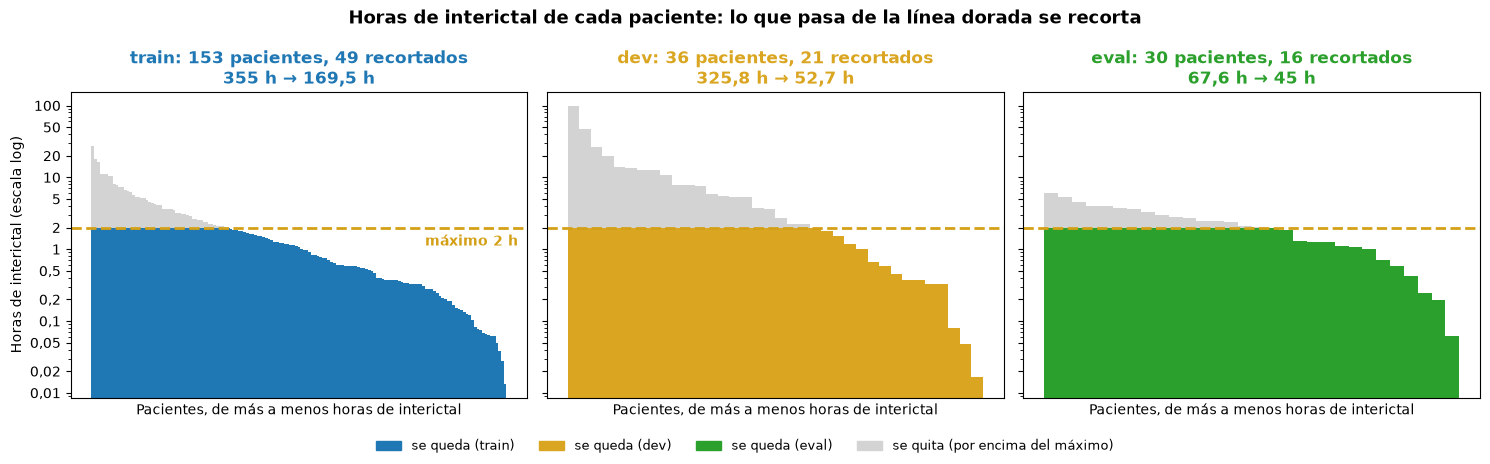

In [51]:
# Figura: horas de 💤 interictal de cada paciente, de más a menos, con el máximo
fig, axes = plt.subplots(1, len(SPLITS), figsize=(15, 4.6), sharey=True)
for ax, s in zip(axes, SPLITS):
    h = horas_antes.get(s, pd.Series(dtype=float)).sort_values(ascending=False)
    if h.empty:
        ax.text(0.5, 0.5, 'sin ventanas interictales', transform=ax.transAxes, ha='center', color='gray')
        ax.set_title(s, color=COLORES_SPLIT[s], fontweight='bold')
        ax.set_xticks([])
        continue
    x = np.arange(len(h))
    recortado = h.clip(upper=MAX_HORAS_INTERICTAL_POR_PACIENTE)
    ax.bar(x, h.values, width=1.0, color='lightgray', label='lo que se quita')
    ax.bar(x, recortado.values, width=1.0, color=COLORES_SPLIT[s], label='lo que se queda')
    ax.axhline(MAX_HORAS_INTERICTAL_POR_PACIENTE, color=COLOR_DESTACADO, ls='--', lw=2)
    n_rec = int((h > MAX_HORAS_INTERICTAL_POR_PACIENTE + 1e-9).sum())
    ax.set_title(f'{s}: {len(h)} pacientes, {n_rec} recortados\n'
                 f'{numero_legible(round(h.sum(), 1))} h → {numero_legible(round(recortado.sum(), 1))} h',
                 color=COLORES_SPLIT[s], fontweight='bold')
    ax.set_xlabel('Pacientes, de más a menos horas de interictal')
    ax.set_xticks([])
    ax.set_yscale('log')
axes[0].set_ylabel('Horas de interictal (escala log)')
eje_log_legible(axes[0], 'y')
axes[0].text(0.98, MAX_HORAS_INTERICTAL_POR_PACIENTE * 0.8, f'máximo {MAX_HORAS_INTERICTAL_POR_PACIENTE} h',
             transform=axes[0].get_yaxis_transform(), ha='right', va='top', color=COLOR_DESTACADO, fontweight='bold')
fig.legend(handles=[Patch(color=COLORES_SPLIT[s], label=f'se queda ({s})') for s in SPLITS]
           + [Patch(color='lightgray', label='se quita (por encima del máximo)')],
           loc='lower center', ncol=4, fontsize=9, frameon=False)
fig.suptitle('Horas de interictal de cada paciente: lo que pasa de la línea dorada se recorta', fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(RUTA_FIGURAS / 'maximo_por_paciente.png', dpi=150, bbox_inches='tight')
plt.show()

👀 **Cómo leer la figura.** Una barra por paciente, de más a menos horas de 💤 interictal (escala log). La parte de color es lo que se queda; la gris, lo que sobra por encima de la línea dorada (el máximo). Si casi todo es de color, el máximo apenas toca nada; si unos pocos pacientes tienen mucho gris, son los que dominaban la partición.

## 5. Un conjunto por modelo

Cada modelo tiene su ⏳ preictal (las columnas `en_...` de `03`) y sus pacientes:

| Conjunto | Para qué | ⏳ preictal | 💤 interictal | Particiones |
|---|---|---|---|---|
| `general` | Modelo general (Fase 3), el principal | `en_general` (de 4 a 1 min antes) | todos los pacientes | train, dev, eval |
| `umbral_<U>min` | Comparar umbrales (Fase 3) | `en_umbral_<U>min` (de U a 1 min antes) | todos los pacientes | train, dev, eval |
| `grupo_<grupo>` | Modelo de un grupo de inicio | `en_modelo_grupo` de ese grupo (umbrales de `umbrales.py`) | **solo pacientes con crisis de ese grupo** | train, dev, eval |
| `test_comun` | Mismo test para todos los umbrales | `en_test_comun` (de 2 a 1 min antes) | todos los pacientes | **solo eval** |
| `clasificacion` | Clasificar el tipo de crisis (Fase 4) | — (⚡ ictales, etiqueta = tipo) | — | train, dev, eval |

**Por qué los modelos de grupo solo usan 💤 interictales de pacientes de su grupo.** Un modelo de 🔹 ausencias se usaría con pacientes que se sabe que tienen ausencias. Si se evaluara con 💤 interictales de pacientes que nunca tienen ausencias, se mediría otra cosa.

En todos, las 💤 interictales son las que quedan **tras el máximo** de la sección 4.

In [52]:
pre = usables.clase == 'preictal'
inter = (usables.clase == 'interictal') & usables.dentro_del_maximo

# Definición de cada conjunto: (qué es, máscara de sus ⏳ preictales, ¿solo 💤 interictales de pacientes con ⏳ preictales de este conjunto?, particiones)
DEFINICION = {'general': ('modelo general (de 4 a 1 min antes)', pre & usables.en_general, False, SPLITS)}
for u in UMBRALES_LEADIN_COMPARACION_MIN:
    DEFINICION[f'umbral_{u}min'] = (f'comparación de umbrales (de {u} a 1 min antes)', pre & usables[f'en_umbral_{u}min'], False, SPLITS)
for g in GRUPOS:
    DEFINICION[f'grupo_{g}'] = (f'modelo del grupo {g} {ICONO_GRUPO[g]}', pre & usables.en_modelo_grupo & (usables.grupo == g), True, SPLITS)
DEFINICION['test_comun'] = ('test común entre umbrales (de 2 a 1 min antes)', pre & usables.en_test_comun, False, ['eval'])

def armar_conjunto(mascara_pre, solo_pacientes_del_conjunto, particiones):
    """Ventanas ⏳ preictales del conjunto + 💤 interictales (tras el máximo) de sus particiones y, si toca, solo de sus pacientes."""
    mascara_inter = inter.copy()
    if solo_pacientes_del_conjunto:
        mascara_inter &= usables.patient.isin(usables.loc[mascara_pre, 'patient'])
    c = usables[(mascara_pre | mascara_inter) & usables.split.isin(particiones)].copy()
    c['etiqueta'] = (c.clase == 'preictal').astype(int)          # 1 = ⏳ preictal, 0 = 💤 interictal
    return c

conjuntos = {nombre: armar_conjunto(m, solo, parts) for nombre, (_, m, solo, parts) in DEFINICION.items()}
conjuntos['clasificacion'] = usables[usables.clase == 'ictal'].assign(etiqueta=lambda d: d.tipo)

tabla_conjuntos = pd.DataFrame({
    nombre: {'qué es': DEFINICION[nombre][0] if nombre in DEFINICION else 'clasificación de tipos (⚡ ictal, etiqueta = tipo)',
             'pacientes': c.patient.nunique(),
             'crisis': c.crisis_id.nunique(),
             '⏳ preictal': int((c.clase == 'preictal').sum()),
             '💤 interictal': int((c.clase == 'interictal').sum()),
             '⚡ ictal': int((c.clase == 'ictal').sum())}
    for nombre, c in conjuntos.items()}).T
tabla_conjuntos.index.name = 'conjunto'
display(tabla_conjuntos)

,qué es,pacientes,crisis,⏳ preictal,💤 interictal,⚡ ictal
conjunto,,,,,,
general,modelo general (de 4 a 1 min antes),228,490,41578,240484,0
umbral_2min,comparación de umbrales (de 2 a 1 min antes),230,665,18034,240484,0
umbral_3min,comparación de umbrales (de 3 a 1 min antes),229,555,30950,240484,0
umbral_4min,comparación de umbrales (de 4 a 1 min antes),228,490,41578,240484,0
umbral_5min,comparación de umbrales (de 5 a 1 min antes),227,368,41655,240484,0
umbral_7min,comparación de umbrales (de 7 a 1 min antes),223,158,27188,240484,0
umbral_10min,comparación de umbrales (de 10 a 1 min antes),222,63,16501,240484,0
umbral_15min,comparación de umbrales (de 15 a 1 min antes),219,25,10407,240484,0
grupo_focal,modelo del grupo focal ♦️,103,344,29163,121402,0


👀 **Cómo leer la tabla.** Una fila por conjunto, sumando todas sus particiones. Fíjate en que `general` y los `umbral_...` comparten las mismas 💤 interictales y solo cambian sus ⏳ preictales, y en que los `grupo_...` tienen menos 💤 interictales, porque solo usan las de sus pacientes.

## 6. Equilibrar solo el entrenamiento, paciente a paciente

En el **entrenamiento** de cada conjunto, `equilibrar_por_paciente` deja que cada paciente aporte `RATIO_ENTRENAMIENTO` 💤 interictales por cada ⏳ preictal suya y marca esas ventanas con `entrenamiento_equilibrado = True`. Lo demás se queda en la tabla, pero a False.

Con `EQUILIBRADO_EXACTO = True` el reparto es **exacto** en cada paciente: a quien le faltan 💤 interictales se le sortean también las ⏳ preictales, y quien no tiene 💤 interictales no entra en el entrenamiento (sus ventanas siguen en la tabla, a False). Cuesta algunas ⏳ preictales, pero así **ningún paciente tira hacia una clase** y sus rasgos fijos (equipo, canales a 0) no le sirven a la red como pista.

- **Entrenamiento** = 🔵 train. En los grupos con validación cruzada (`GRUPOS_VALIDACION_CRUZADA`) es **train + dev**, porque dev también se usa para entrenar en algún pliegue (sección 7). Al equilibrar paciente a paciente, cada pliegue de entrenamiento sale equilibrado solo.
- **dev y eval** se quedan como están (solo con el máximo de la sección 4).
- `clasificacion` no se equilibra aquí: el desbalance entre tipos lo trata la Fase 4.

La tabla también da el **peso de cada clase** por si en la Fase 3 se prefiere entrenar con **todas** las ventanas de train y compensar con pesos (`pesos_de_clase`).

In [53]:
def particiones_de_entrenamiento(nombre):
    grupo_conjunto = nombre.removeprefix('grupo_') if nombre.startswith('grupo_') else None
    return ['train', 'dev'] if grupo_conjunto in GRUPOS_VALIDACION_CRUZADA else ['train']

for nombre, c in conjuntos.items():
    if nombre == 'clasificacion':
        continue
    en_entrenamiento = c.split.isin(particiones_de_entrenamiento(nombre))
    c['entrenamiento_equilibrado'] = False
    if en_entrenamiento.any():
        c.loc[en_entrenamiento, 'entrenamiento_equilibrado'] = equilibrar_por_paciente(c[en_entrenamiento], RATIO_ENTRENAMIENTO, exacto=EQUILIBRADO_EXACTO)

def resumen_split(c, s, nombre):
    g = c[c.split == s]
    n_pre, n_inter = int((g.clase == 'preictal').sum()), int((g.clase == 'interictal').sum())
    eq = g[g.entrenamiento_equilibrado]
    entrena = s in particiones_de_entrenamiento(nombre)
    pesos = pesos_de_clase(g.clase) if entrena and n_pre and n_inter else {}
    return {'pacientes': g.patient.nunique(), 'crisis': g.crisis_id.nunique(),
            '⏳ preictal': n_pre, '💤 interictal': n_inter,
            '💤 interictales por cada ⏳ preictal': n_inter / n_pre if n_pre else np.nan,
            '⏳ preictal equilibrado': int((eq.clase == 'preictal').sum()) if entrena else np.nan,
            '💤 interictal equilibrado': int((eq.clase == 'interictal').sum()) if entrena else np.nan,
            'peso ⏳ preictal (si se entrena con todo)': pesos.get('preictal', np.nan)}

resumen = pd.DataFrame({(nombre, s): resumen_split(c, s, nombre)
                        for nombre, c in conjuntos.items() if nombre != 'clasificacion'
                        for s in DEFINICION[nombre][3]}).T
resumen.index.names = ['conjunto', 'split']
resumen.to_csv(RUTA_RESULTADOS / 'resumen_conjuntos.csv')
mostrar_fichero(RUTA_RESULTADOS / 'resumen_conjuntos.csv',
                'una fila por conjunto y partición: pacientes, crisis, ventanas ⏳ preictales y 💤 interictales, cuántas 💤 interictales hay por cada ⏳ preictal, cuántas quedan en el '
                'entrenamiento equilibrado (vacío en las particiones que no se entrenan) y el peso de ⏳ preictal para entrenar con todo')
display(Markdown('**Todos los conjuntos, por partición:**'))
display(con_separadores(tabla_con_iconos(resumen.rename(columns=str))))

💾 **Guardado `resumen_conjuntos.csv`** · 2,8 KB · 34 filas × 10 columnas  
*Qué guarda:* una fila por conjunto y partición: pacientes, crisis, ventanas ⏳ preictales y 💤 interictales, cuántas 💤 interictales hay por cada ⏳ preictal, cuántas quedan en el entrenamiento equilibrado (vacío en las particiones que no se entrenan) y el peso de ⏳ preictal para entrenar con todo. *Abajo:* las 5 primeras filas.

,conjunto,split,pacientes,crisis,⏳ preictal,💤 interictal,💤 interictales por cada ⏳ preictal,⏳ preictal equilibrado,💤 interictal equilibrado,peso ⏳ preictal (si se entrena con todo)
0,general,🔵 train,162.0,259.0,22006.0,152536.0,6.931564,22006.0,18443.0,3.965782
1,general,🟡 dev,36.0,133.0,11190.0,47429.0,4.238517,NaN,NaN,NaN
2,general,🟢 eval,30.0,98.0,8382.0,40519.0,4.834049,NaN,NaN,NaN
3,umbral_2min,🔵 train,163.0,356.0,9690.0,152536.0,15.741589,9690.0,9225.0,8.370795
4,umbral_2min,🟡 dev,37.0,196.0,5259.0,47429.0,9.018635,NaN,NaN,NaN


**Todos los conjuntos, por partición:**

👀 **Cómo leer la tabla.** Una fila por conjunto y partición. `💤 interictales por cada ⏳ preictal` es el desbalance real. En las filas de entrenamiento, `⏳ preictal equilibrado` y `💤 interictal equilibrado` deberían salir **iguales** con `EQUILIBRADO_EXACTO = True` (con `RATIO_ENTRENAMIENTO = 1`); con `False`, si 💤 sale por debajo, algún paciente tiene menos 💤 interictales que ⏳ preictales. Fíjate también en que `⏳ preictal equilibrado` puede ser menor que `⏳ preictal`: son las que se sortean fuera para igualar. En dev y eval esas columnas van vacías, porque no se equilibran. `peso ⏳ preictal` es lo que pesaría cada ventana ⏳ preictal si en vez de equilibrar se entrenara con todo.

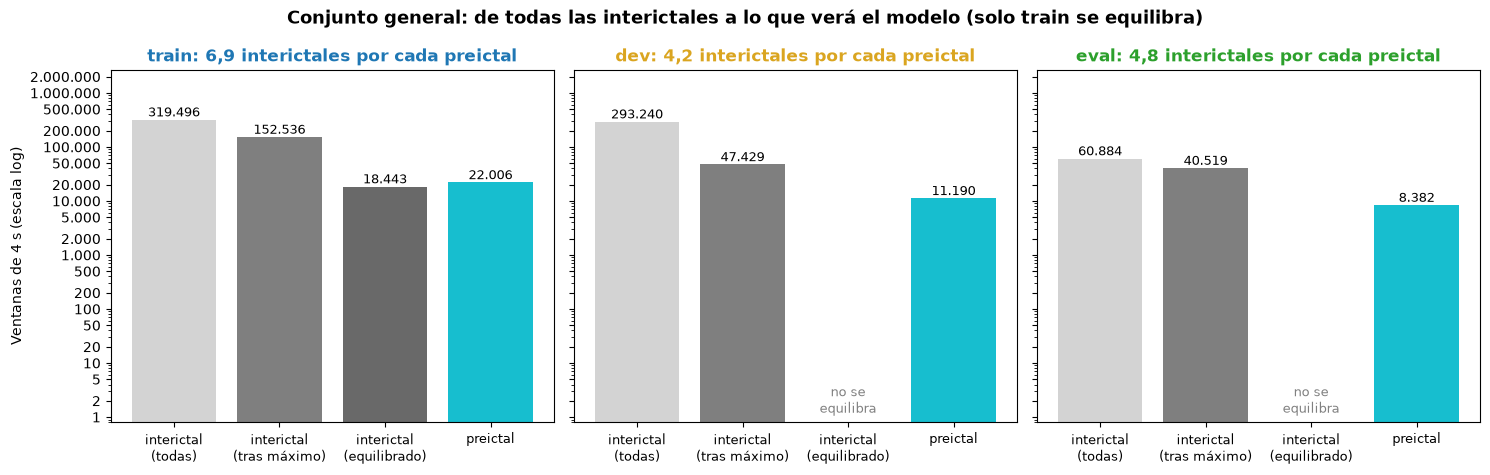

In [54]:
# Figura: el conjunto general, antes y después del máximo y del equilibrado
general = conjuntos['general']
todas_inter = usables[usables.clase == 'interictal']
pasos = [('interictal\n(todas)', lambda s: (todas_inter.split == s).sum(), 'lightgray'),
         ('interictal\n(tras máximo)', lambda s: ((general.split == s) & (general.clase == 'interictal')).sum(), COLORES_PERIODO['interictal']),
         ('interictal\n(equilibrado)', lambda s: ((general.split == s) & (general.clase == 'interictal') & general.entrenamiento_equilibrado).sum(), 'dimgray'),
         ('preictal', lambda s: ((general.split == s) & (general.clase == 'preictal')).sum(), COLORES_PERIODO['preictal'])]
fig, axes = plt.subplots(1, len(SPLITS), figsize=(15, 4.8), sharey=True)
for ax, s in zip(axes, SPLITS):
    valores = [int(f(s)) for _, f, _ in pasos]
    for k, ((nombre, _, color), v) in enumerate(zip(pasos, valores)):
        no_aplica = k == 2 and s not in particiones_de_entrenamiento('general')
        if v > 0:
            ax.bar(k, v, color=color)
        ax.text(k, v * 1.15 if v > 0 else 1.2, 'no se\nequilibra' if no_aplica else (numero_legible(v) if v > 0 else 'sin\nventanas'),
                ha='center', fontsize=9, color='gray' if no_aplica or v == 0 else 'black')
    ax.set_xticks(range(len(pasos)), [n for n, _, _ in pasos], fontsize=9)
    ax.set_xlim(-0.6, len(pasos) - 0.4)
    ratio = valores[1] / valores[3] if valores[3] else np.nan
    ax.set_title(f'{s}: {numero_legible(round(ratio, 1)) if pd.notna(ratio) else "—"} interictales por cada preictal',
                 color=COLORES_SPLIT[s], fontweight='bold')
    ax.set_yscale('log')
techo = max(1, len(todas_inter), int((general.clase == 'preictal').sum())) * 4
for ax in axes:
    ax.set_ylim(0.8, techo)                                   # deja hueco para los números encima de las barras
eje_log_legible(axes[0], 'y')
axes[0].set_ylabel(f'Ventanas de {VENTANA_S} s (escala log)')
fig.suptitle('Conjunto general: de todas las interictales a lo que verá el modelo (solo train se equilibra)', fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'equilibrado_general.png', dpi=150, bbox_inches='tight')
plt.show()

👀 **Cómo leer la figura.** Un panel por partición, para el modelo general. De izquierda a derecha: todas las 💤 interictales usables, las que quedan tras el máximo por paciente, las que quedan en el entrenamiento equilibrado (solo en train) y las ⏳ preictales. En train, la tercera barra debería ser casi igual de alta que la cuarta. En dev y eval no se equilibra: el título dice cuántas 💤 interictales hay por cada ⏳ preictales, que es el desbalance con el que se medirá el modelo.

## 7. Pliegues para la validación cruzada por paciente (🟩 absz (🔹))

En 🟢 eval solo hay **un** paciente con ausencias: su cifra no dice si el modelo generaliza. Por eso, además de eval, el modelo de 🔹 ausencias se valida con **validación cruzada por paciente en train + dev** (12 pacientes con todos los datos).

`pliegues_por_paciente` reparte esos pacientes en `N_PLIEGUES` pliegues, **cada paciente entero en uno**, buscando que todos tengan un número de ⏳ preictales parecido. En la Fase 3 se entrena con todos los pliegues menos uno (con `entrenamiento_equilibrado`) y se valida con el que queda (con **todas** sus ventanas, sin equilibrar), rotando.

In [55]:
pliegues = {}
for g in GRUPOS_VALIDACION_CRUZADA:
    nombre = f'grupo_{g}'
    c = conjuntos[nombre]
    entrenamiento = c[c.split.isin(['train', 'dev'])]
    preictales = entrenamiento[entrenamiento.clase == 'preictal'].groupby('patient').size()
    c['pliegue'] = pd.NA
    if preictales.empty:
        print(f'{con_icono(g)}: no hay pacientes con ⏳ preictales en train + dev (normal en modo prueba si no hay ese grupo).')
        continue
    pliegue = pliegues_por_paciente(preictales, N_PLIEGUES)
    c['pliegue'] = c.patient.map(pliegue).astype('Int64')       # eval y los pacientes sin ⏳ preictales se quedan sin pliegue
    tabla = pd.DataFrame({
        'split': entrenamiento.groupby('patient').split.first(),
        'pliegue': pliegue,
        'crisis': entrenamiento[entrenamiento.clase == 'preictal'].groupby('patient').crisis_id.nunique(),
        '⏳ preictal': preictales,
        '💤 interictal': entrenamiento[entrenamiento.clase == 'interictal'].groupby('patient').size(),
        '💤 interictal equilibrado': entrenamiento[(entrenamiento.clase == 'interictal') & entrenamiento.entrenamiento_equilibrado].groupby('patient').size(),
    }).loc[pliegue.index].fillna(0)
    tabla[['pliegue', 'crisis', '⏳ preictal', '💤 interictal', '💤 interictal equilibrado']] = \
        tabla[['pliegue', 'crisis', '⏳ preictal', '💤 interictal', '💤 interictal equilibrado']].astype(int)
    tabla.index.name = 'patient'
    pliegues[g] = tabla
    tabla.to_csv(RUTA_RESULTADOS / f'pliegues_{g}.csv')
    mostrar_fichero(RUTA_RESULTADOS / f'pliegues_{g}.csv',
                    f'una fila por paciente de {g} en train + dev: su partición original, el pliegue al que va (0, 1, 2…), '
                    'sus crisis y ventanas ⏳ preictales, sus 💤 interictales y cuántas 💤 interictales entran en el entrenamiento equilibrado')
    por_pliegue = tabla.groupby('pliegue')[['crisis', '⏳ preictal', '💤 interictal equilibrado']].sum()
    por_pliegue.insert(0, 'pacientes', tabla.groupby('pliegue').size())
    display(Markdown(f'**{con_icono(g)}: cómo quedan los pliegues**'))
    display(por_pliegue)

💾 **Guardado `pliegues_ausencia.csv`** · 447 B · 12 filas × 7 columnas  
*Qué guarda:* una fila por paciente de ausencia en train + dev: su partición original, el pliegue al que va (0, 1, 2…), sus crisis y ventanas ⏳ preictales, sus 💤 interictales y cuántas 💤 interictales entran en el entrenamiento equilibrado. *Abajo:* las 5 primeras filas.

,patient,split,pliegue,crisis,⏳ preictal,💤 interictal,💤 interictal equilibrado
0,aaaaaazz,🟡 dev,0,9,204,332,204
1,aaaaacrb,🔵 train,0,2,46,108,46
2,aaaaaewf,🟡 dev,0,2,48,522,48
3,aaaaaccj,🔵 train,1,8,186,361,186
4,aaaaadyf,🔵 train,1,3,69,521,69


**🔹 ausencia: cómo quedan los pliegues**

,pacientes,crisis,⏳ preictal,💤 interictal equilibrado
pliegue,,,,
0,3,13,298,298
1,3,12,279,279
2,4,13,301,132
3,2,14,322,322


👀 **Cómo leer las tablas.** La primera, un paciente por fila y a qué pliegue va. La segunda, cada pliegue: lo ideal es que todos tengan un número de ⏳ preictales parecido. Si hay menos pacientes que `N_PLIEGUES`, cada paciente es su propio pliegue (validación "deja uno fuera").

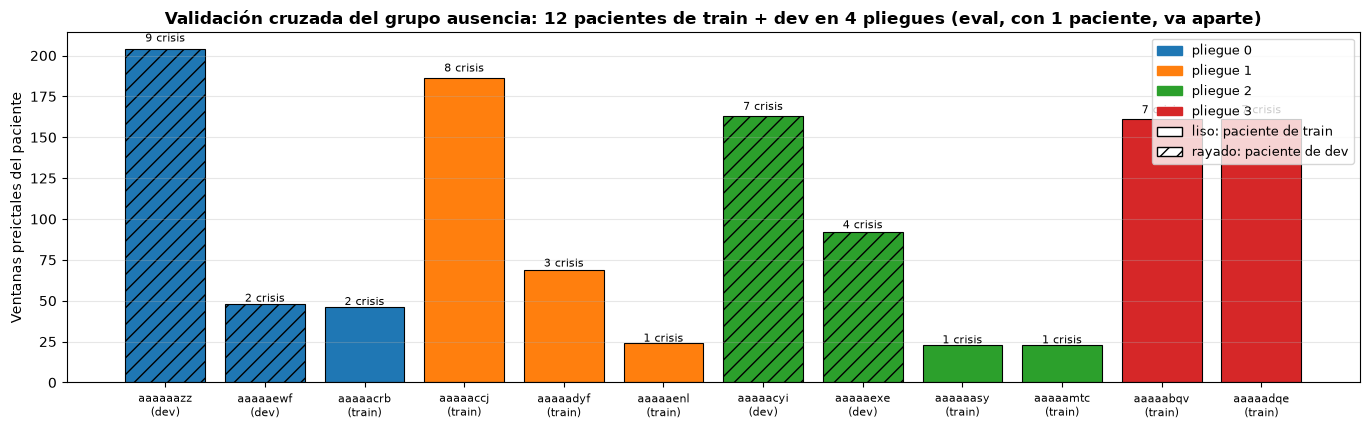

In [56]:
# Figura: pacientes de cada grupo con validación cruzada, coloreados por pliegue
COLORES_PLIEGUE = plt.get_cmap('tab10').colors
for g, tabla in pliegues.items():
    tabla_fig = tabla.sort_values(['pliegue', '⏳ preictal'], ascending=[True, False])
    fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(tabla_fig) + 3), 4.4))
    x = np.arange(len(tabla_fig))
    barras = ax.bar(x, tabla_fig['⏳ preictal'], color=[COLORES_PLIEGUE[p % 10] for p in tabla_fig.pliegue],
                    edgecolor='black', linewidth=0.8, hatch=['//' if s == 'dev' else '' for s in tabla_fig.split])
    for xi, (paciente, fila) in zip(x, tabla_fig.iterrows()):
        ax.text(xi, fila['⏳ preictal'] * 1.02 + 0.5, f'{fila.crisis} crisis', ha='center', fontsize=8)
    ax.set_xticks(x, [f'{p}\n({s})' for p, s in zip(tabla_fig.index, tabla_fig.split)], fontsize=8)
    ax.set_ylabel('Ventanas preictales del paciente')
    leyenda = [Patch(color=COLORES_PLIEGUE[p % 10], label=f'pliegue {p}') for p in sorted(tabla_fig.pliegue.unique())]
    leyenda += [Patch(facecolor='white', edgecolor='black', label='liso: paciente de train'),
                Patch(facecolor='white', edgecolor='black', hatch='//', label='rayado: paciente de dev')]
    ax.legend(handles=leyenda, fontsize=9, loc='upper right')
    n_eval = conjuntos[f'grupo_{g}'].query("split == 'eval' and clase == 'preictal'").patient.nunique()
    ax.set_title(f'Validación cruzada del grupo {g}: {len(tabla_fig)} pacientes de train + dev en '
                 f'{tabla_fig.pliegue.nunique()} pliegues (eval, con {n_eval} paciente{"s" if n_eval != 1 else ""}, va aparte)',
                 fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / f'pliegues_{g}.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Una barra por paciente, con sus ventanas ⏳ preictales y sus crisis encima. El **color** dice a qué pliegue va; el **rayado**, que el paciente viene de dev (lisos: train). Un pliegue con mucha más altura total que los demás pesaría más en la media de la validación cruzada.

## 8. Los conjuntos → `conjuntos/<modelo>.csv`

<div style="background:#fff6d8; color:#1a1a1a; border:2px solid #d4a017; border-radius:8px; padding:10px 14px">
<span style="color:#1a1a1a">🏆 <b style="color:#1a1a1a">El resultado de este notebook.</b> Una tabla por modelo con sus ventanas, su partición, su etiqueta (1 = ⏳ preictal, 0 = 💤 interictal) y si entra en el entrenamiento equilibrado. La Fase 3 solo tiene que leer la de su modelo y cargar cada ventana del <b style="color:#1a1a1a">.npy</b> con <b style="color:#1a1a1a">ruta</b> y <b style="color:#1a1a1a">muestra_inicio</b>.</span>
</div>

Antes de guardar se comprueba que:

1. Ningún paciente está en dos particiones **dentro de un conjunto**.
2. dev y eval **no se han equilibrado** (salvo dev en los grupos con validación cruzada).
3. En el entrenamiento equilibrado, cada paciente tiene **como mucho** `RATIO_ENTRENAMIENTO` 💤 interictales por cada ⏳ preictal y, con `EQUILIBRADO_EXACTO`, **exactamente** esas.
4. Ningún paciente tiene más 💤 interictales que el **máximo**.
5. `test_comun` solo tiene ventanas de **eval**, y ninguna ventana descartada en `03` se ha colado.

In [57]:
errores = {'1. pacientes en dos particiones': 0, '2. dev/eval equilibrados por error': 0,
           '3. pacientes con más 💤 interictales que ⏳ preictales × ratio': 0, '4. pacientes por encima del máximo': 0,
           '5. test_comun fuera de eval o ventanas descartadas': 0}
descartadas = set(ventanas_todas.loc[ventanas_todas.rechazada, 'id_ventana'])
for nombre, c in conjuntos.items():
    errores['1. pacientes en dos particiones'] += int((c.groupby('patient').split.nunique() > 1).sum())
    errores['5. test_comun fuera de eval o ventanas descartadas'] += int(c.id_ventana.isin(descartadas).sum())
    if nombre == 'clasificacion':
        continue
    fuera = ~c.split.isin(particiones_de_entrenamiento(nombre))
    errores['2. dev/eval equilibrados por error'] += int((fuera & c.entrenamiento_equilibrado).sum())
    eq = c[c.entrenamiento_equilibrado]
    cuenta = eq.groupby(['patient', 'clase']).size().unstack(fill_value=0).reindex(columns=['interictal', 'preictal'], fill_value=0)
    esperadas = np.round(cuenta.preictal * RATIO_ENTRENAMIENTO)
    fuera_de_ratio = (cuenta.interictal != esperadas) if EQUILIBRADO_EXACTO else (cuenta.interictal > esperadas)
    errores['3. pacientes con más 💤 interictales que ⏳ preictales × ratio'] += int(fuera_de_ratio.sum())
    errores['4. pacientes por encima del máximo'] += int((c[c.clase == 'interictal'].groupby('patient').size() > MAX_VENTANAS_INTERICTAL).sum())
errores['5. test_comun fuera de eval o ventanas descartadas'] += int((conjuntos['test_comun'].split != 'eval').sum())
for comprobacion, n in errores.items():
    print(f'{"✅" if n == 0 else "🔴"} {comprobacion} (debe ser 0): {n}')
assert all(n == 0 for n in errores.values()), '🔴 Alguna comprobación ha fallado.'

✅ 1. pacientes en dos particiones (debe ser 0): 0
✅ 2. dev/eval equilibrados por error (debe ser 0): 0
✅ 3. pacientes con más 💤 interictales que ⏳ preictales × ratio (debe ser 0): 0
✅ 4. pacientes por encima del máximo (debe ser 0): 0
✅ 5. test_comun fuera de eval o ventanas descartadas (debe ser 0): 0


In [58]:
COLUMNAS = ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'tipo', 'grupo', 'crisis_id',
            'ruta', 'muestra_inicio', 'segundos_hasta_crisis', 'entrenamiento_equilibrado', 'pliegue']
for nombre, c in conjuntos.items():
    columnas = [col for col in COLUMNAS if col in c.columns]
    orden = c.split.map({s: k for k, s in enumerate(SPLITS)})
    c.assign(_orden=orden).sort_values(['_orden', 'patient', 'id_ventana'])[columnas] \
        .to_csv(RUTA_CONJUNTOS / f'{nombre}.csv', index=False)

mostrar_fichero(RUTA_CONJUNTOS / 'general.csv',
                'el conjunto del modelo general: una fila por ventana, con su partición y paciente, su etiqueta (1 = ⏳ preictal, 0 = 💤 interictal), '
                'dónde leer su señal (ruta + muestra_inicio) y si entra en el entrenamiento equilibrado')
for nombre in conjuntos:
    if nombre != 'general':
        mostrar_fichero(RUTA_CONJUNTOS / f'{nombre}.csv', f'el conjunto {nombre} (mismas columnas que general.csv'
                        + (', más el pliegue de cada paciente' if nombre.removeprefix('grupo_') in GRUPOS_VALIDACION_CRUZADA else '')
                        + ('; la etiqueta es el tipo de crisis y no hay columna de equilibrado' if nombre == 'clasificacion' else '') + ')',
                        filas=3)

💾 **Guardado `general.csv`** · 50,3 MB · 282.062 filas × 13 columnas  
*Qué guarda:* el conjunto del modelo general: una fila por ventana, con su partición y paciente, su etiqueta (1 = ⏳ preictal, 0 = 💤 interictal), dónde leer su señal (ruta + muestra_inicio) y si entra en el entrenamiento equilibrado. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,entrenamiento_equilibrado
0,aaaaaaac_s004_t000_interictal_000000000_000000000,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,0,NaN,False
1,aaaaaaac_s004_t000_interictal_000000000_000001024,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,1024,NaN,False
2,aaaaaaac_s004_t000_interictal_000000000_000002048,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,2048,NaN,False
3,aaaaaaac_s004_t000_interictal_000000000_000003072,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,3072,NaN,False
4,aaaaaaac_s004_t000_interictal_000000000_000004096,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,4096,NaN,False


💾 **Guardado `umbral_2min.csv`** · 45,5 MB · 258.518 filas × 13 columnas  
*Qué guarda:* el conjunto umbral_2min (mismas columnas que general.csv). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,entrenamiento_equilibrado
0,aaaaaaac_s004_t000_interictal_000000000_000000000,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,0,NaN,False
1,aaaaaaac_s004_t000_interictal_000000000_000001024,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,1024,NaN,False
2,aaaaaaac_s004_t000_interictal_000000000_000002048,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,2048,NaN,False


💾 **Guardado `umbral_3min.csv`** · 48,1 MB · 271.434 filas × 13 columnas  
*Qué guarda:* el conjunto umbral_3min (mismas columnas que general.csv). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,entrenamiento_equilibrado
0,aaaaaaac_s004_t000_interictal_000000000_000000000,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,0,NaN,False
1,aaaaaaac_s004_t000_interictal_000000000_000001024,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,1024,NaN,False
2,aaaaaaac_s004_t000_interictal_000000000_000002048,🔵 train,aaaaaaac,aaaaaaac_s004_t000,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaaac_s004_t000_interictal...,2048,NaN,False


... (16 outputs left out)

💾 **Guardado `test_comun.csv`** · 7,6 MB · 43.604 filas × 13 columnas  
*Qué guarda:* el conjunto test_comun (mismas columnas que general.csv). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,entrenamiento_equilibrado
0,aaaaaarq_s014_t001_interictal_000000000_000000000,🟢 eval,aaaaaarq,aaaaaarq_s014_t001,💤 interictal,0,nan,nan,NaN,eval/interictal/aaaaaarq_s014_t001_interictal_...,0,NaN,False
1,aaaaaarq_s014_t001_interictal_000000000_000003072,🟢 eval,aaaaaarq,aaaaaarq_s014_t001,💤 interictal,0,nan,nan,NaN,eval/interictal/aaaaaarq_s014_t001_interictal_...,3072,NaN,False
2,aaaaaarq_s014_t001_interictal_000000000_000007168,🟢 eval,aaaaaarq,aaaaaarq_s014_t001,💤 interictal,0,nan,nan,NaN,eval/interictal/aaaaaarq_s014_t001_interictal_...,7168,NaN,False


💾 **Guardado `clasificacion.csv`** · 14,9 MB · 81.145 filas × 12 columnas  
*Qué guarda:* el conjunto clasificacion (mismas columnas que general.csv; la etiqueta es el tipo de crisis y no hay columna de equilibrado). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis
0,aaaaaaac_s001_t000_ictal_000036887_000000000,🔵 train,aaaaaaac,aaaaaaac_s001_t000,⚡ ictal,cpsz,🟧 cpsz (♦️),♦️ focal,aaaaaaac_s001_t000_c00,train/ictal/aaaaaaac_s001_t000_ictal_000036887...,0,NaN
1,aaaaaaac_s001_t000_ictal_000036887_000000512,🔵 train,aaaaaaac,aaaaaaac_s001_t000,⚡ ictal,cpsz,🟧 cpsz (♦️),♦️ focal,aaaaaaac_s001_t000_c00,train/ictal/aaaaaaac_s001_t000_ictal_000036887...,512,NaN
2,aaaaaaac_s001_t000_ictal_000036887_000001024,🔵 train,aaaaaaac,aaaaaaac_s001_t000,⚡ ictal,cpsz,🟧 cpsz (♦️),♦️ focal,aaaaaaac_s001_t000_c00,train/ictal/aaaaaaac_s001_t000_ictal_000036887...,1024,NaN


In [59]:
DESCRIPCION_COLUMNAS = {
    'id_ventana': 'Identificador único: tramo + muestra de inicio', 'split': 'Partición', 'patient': 'Paciente',
    'file': 'Fichero EDF', 'clase': '💤 interictal, ⏳ preictal (o ⚡ ictal en clasificacion)',
    'etiqueta': '1 = ⏳ preictal, 0 = 💤 interictal (en clasificacion, el tipo de crisis)',
    'tipo': 'Tipo de crisis (⏳ preictal y ⚡ ictal)', 'grupo': 'Grupo de inicio (⏳ preictal y ⚡ ictal)', 'crisis_id': 'Crisis a la que pertenece (⏳ preictal y ⚡ ictal)',
    'ruta': 'Su .npy, dentro de 02_preprocesado/senales/', 'muestra_inicio': 'Muestra del .npy en la que empieza',
    'segundos_hasta_crisis': '⏳ preictal: segundos desde el final de la ventana hasta la crisis',
    'entrenamiento_equilibrado': 'Entra en el entrenamiento equilibrado (sección 6)',
    'pliegue': 'Pliegue del paciente en la validación cruzada (solo grupos de GRUPOS_VALIDACION_CRUZADA)',
}
leido = pd.read_csv(RUTA_CONJUNTOS / 'general.csv')
columnas_csv = pd.DataFrame({'qué es': [DESCRIPCION_COLUMNAS[c] for c in COLUMNAS]}, index=pd.Index(COLUMNAS, name='columna'))
ficheros = pd.DataFrame({'ventanas': {f'{n}.csv': len(c) for n, c in conjuntos.items()},
                         'pacientes': {f'{n}.csv': c.patient.nunique() for n, c in conjuntos.items()}})
ficheros.index.name = 'fichero'
mostrar_destacado('conjuntos/: una tabla por modelo',
                  f'<b>{len(conjuntos)} ficheros</b> · el principal, <b>general.csv</b>, tiene {numero_legible(len(leido))} ventanas '
                  f'de {numero_legible(leido.patient.nunique())} pacientes',
                  '<b>Qué significa cada columna</b>', columnas_csv, '<b>Los ficheros</b>', ficheros)

,qué es
columna,
id_ventana,Identificador único: tramo + muestra de inicio
split,Partición
patient,Paciente
file,Fichero EDF
clase,"💤 interictal, ⏳ preictal (o ⚡ ictal en clasificacion)"
etiqueta,"1 = ⏳ preictal, 0 = 💤 interictal (en clasificacion, el tipo de crisis)"
tipo,Tipo de crisis (⏳ preictal y ⚡ ictal)
grupo,Grupo de inicio (⏳ preictal y ⚡ ictal)
crisis_id,Crisis a la que pertenece (⏳ preictal y ⚡ ictal)


## 9. Resumen → `summary.txt`

Los datos y las tablas principales, en texto, para consultarlos sin abrir el notebook.

In [60]:
datos = [
    f'Particiones y balanceo: {config["fecha"]}' + ('  ·  MODO PRUEBA (03 con preprocesado incompleto)' if modo_prueba else ''),
    f'Máximo de 💤 interictal por paciente: {MAX_HORAS_INTERICTAL_POR_PACIENTE} h ({numero_legible(MAX_VENTANAS_INTERICTAL)} ventanas), en todas las particiones',
    f'Entrenamiento equilibrado: {numero_legible(RATIO_ENTRENAMIENTO)} 💤 interictales por cada ⏳ preictal, paciente a paciente' + (' (exacto: ningún paciente tira hacia una clase)' if EQUILIBRADO_EXACTO else '') + '; dev y eval sin equilibrar',
    f'Validación cruzada por paciente: {", ".join(GRUPOS_VALIDACION_CRUZADA)} en train + dev, {N_PLIEGUES} pliegues · semilla {SEMILLA}',
]
tablas_resumen = {
    'Pacientes y ventanas usables por partición': tabla_con_iconos(tabla_particiones),
    'Máximo de 💤 interictal por paciente': tabla_con_iconos(tabla_maximo.round(1)),
    'Conjuntos': tabla_conjuntos,
    'Conjuntos por partición': tabla_con_iconos(resumen.round(2)),
    **{f'Pliegues de {g}': tabla_con_iconos(t) for g, t in pliegues.items()},
}
texto = ('=== Particiones y balanceo (Fase 2 · 04) ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen del reparto en texto, para consultarlo sin abrir el notebook')

display(Markdown('\n'.join(f'- {d}' for d in datos)))
for titulo, tabla in tablas_resumen.items():
    display(Markdown(f'#### {titulo}'))
    display(con_separadores(tabla))

💾 **Guardado `summary.txt`** · 12,5 KB · 91 líneas  
*Qué guarda:* el resumen del reparto en texto, para consultarlo sin abrir el notebook. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== Particiones y balanceo (Fase 2 · 04) ===
2,Particiones y balanceo: 2026-10-30 16:14
3,"Máximo de 💤 interictal por paciente: 2 h (1.800 ventanas), en todas las particiones"
4,"Entrenamiento equilibrado: 1 💤 interictales por cada ⏳ preictal, paciente a paciente; dev y eval sin equilibrar"
5,"Validación cruzada por paciente: ausencia en train + dev, 4 pliegues · semilla 42"


- Particiones y balanceo: 2026-10-30 16:14
- Máximo de 💤 interictal por paciente: 2 h (1.800 ventanas), en todas las particiones
- Entrenamiento equilibrado: 1 💤 interictales por cada ⏳ preictal, paciente a paciente; dev y eval sin equilibrar
- Validación cruzada por paciente: ausencia en train + dev, 4 pliegues · semilla 42

#### Pacientes y ventanas usables por partición

#### Máximo de 💤 interictal por paciente

,pacientes con 💤 interictal,horas 💤 interictal antes,horas 💤 interictal después,pacientes recortados,% del paciente con más 💤 interictal (antes),% del paciente con más 💤 interictal (después)
split,,,,,,
🔵 train,"153,0","355,0","169,5","49,0","7,8","1,2"
🟡 dev,"36,0","325,8","52,7","21,0","30,4","3,8"
🟢 eval,"30,0","67,6","45,0","16,0","8,9","4,4"


#### Conjuntos

,qué es,pacientes,crisis,⏳ preictal,💤 interictal,⚡ ictal
conjunto,,,,,,
general,modelo general (de 4 a 1 min antes),228,490,41.578,240.484,0
umbral_2min,comparación de umbrales (de 2 a 1 min antes),230,665,18.034,240.484,0
umbral_3min,comparación de umbrales (de 3 a 1 min antes),229,555,30.950,240.484,0
umbral_4min,comparación de umbrales (de 4 a 1 min antes),228,490,41.578,240.484,0
umbral_5min,comparación de umbrales (de 5 a 1 min antes),227,368,41.655,240.484,0
umbral_7min,comparación de umbrales (de 7 a 1 min antes),223,158,27.188,240.484,0
umbral_10min,comparación de umbrales (de 10 a 1 min antes),222,63,16.501,240.484,0
umbral_15min,comparación de umbrales (de 15 a 1 min antes),219,25,10.407,240.484,0
grupo_focal,modelo del grupo focal ♦️,103,344,29.163,121.402,0


#### Conjuntos por partición

#### Pliegues de ausencia

,split,pliegue,crisis,⏳ preictal,💤 interictal,💤 interictal equilibrado
patient,,,,,,
aaaaaazz,dev,0,9,204,332,204
aaaaacrb,train,0,2,46,108,46
aaaaaewf,dev,0,2,48,522,48
aaaaaccj,train,1,8,186,361,186
aaaaadyf,train,1,3,69,521,69
aaaaaenl,train,1,1,24,335,24
aaaaaasy,train,2,1,23,1.198,23
aaaaacyi,dev,2,7,163,71,71
aaaaaexe,dev,2,4,92,15,15


## 10. Conclusiones

**1. Ningún paciente se cuela entre particiones**
- Se respeta el reparto por paciente de TUSZ, y se comprueba también dentro de cada conjunto.

**2. Ningún paciente domina**
- Con el máximo de 2 h de 💤 interictal por paciente, el que más tiene ya no se lleva una parte enorme de su partición, ni al entrenar ni al evaluar.

**3. El entrenamiento está equilibrado, y dentro de cada paciente**
- Tantas 💤 interictales como ⏳ preictales por paciente: el modelo no gana nada diciendo siempre "💤 interictal" ni reconociendo al paciente. dev y eval se quedan con su desbalance real, así que sus métricas serán honestas.

**4. Cada modelo tiene su conjunto, listo para la Fase 3**
- General, comparación de umbrales, grupos de inicio, test común y clasificación. Para 🟩 absz (🔹) hay además pliegues por paciente en train + dev, para no depender del único paciente de eval.

> ✏️ Las cifras (horas recortadas, desbalance de dev y eval, pliegues) están en las secciones 4 a 7 y en `summary.txt`. **En modo prueba no son representativas**: se revisan con el preprocesado completo.

## 11. Archivos generados y siguiente paso

En `outputs/fase_02/04_particiones_y_balanceo/`:

- `configuracion.json`: máximo por paciente, ratio, pliegues, semilla, versiones y fecha.
- `conjuntos/<modelo>.csv`: **una tabla por modelo** (`general`, `umbral_<U>min`, `grupo_<grupo>`, `test_comun`, `clasificacion`). Es la entrada de la Fase 3.
- `resumen_conjuntos.csv`: ventanas, pacientes, desbalance y pesos de clase de cada conjunto y partición.
- `pliegues_ausencia.csv`: a qué pliegue va cada paciente de 🟩 absz (🔹) de train + dev.
- `summary.txt`: tablas resumen (con iconos).
- `figuras/`: `maximo_por_paciente.png`, `equilibrado_general.png`, `pliegues_ausencia.png`.

**Siguiente paso**: la **Fase 3**. Primero, el **cargador** (lee cada ventana del `.npy` con `ruta` + `muestra_inicio` y la normaliza al vuelo) y una **línea base** sencilla con `conjuntos/general.csv`. Después, el modelo de red neuronal.